# Gaussian Naïve Bayes Classifier

## Project: Credit Risk Scoring System Using Multivariate Statistical Analysis and Machine Learning

### Notebook Objectives

Naïve Bayes is a probabilistic supervised learning algorithm based on Bayes' Theorem. The Gaussian Naïve Bayes variant assumes that numerical features follow a Gaussian (normal) distribution.

Since the dataset has been standardized and transformed using Principal Component Analysis (PCA), Gaussian Naïve Bayes is an appropriate classifier for predicting loan default.

The objectives of this notebook are to:

- Train a Gaussian Naïve Bayes classifier.
- Predict loan default probabilities.
- Evaluate classification performance.
- Analyze the distribution of predicted default probabilities.
- Compare performance with previously developed models.

# Import Required Libraries

The following libraries are used for model training, prediction, evaluation, and visualization.

In [1]:
# ============================================================
# Import Libraries
# ============================================================

import warnings
from pathlib import Path

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

warnings.filterwarnings("ignore")

plt.style.use("ggplot")
sns.set_theme(style="whitegrid")

# Load Training and Testing Data

The PCA-transformed training and testing datasets created during feature engineering are loaded for model development and evaluation.

In [2]:
# ============================================================
# Load Dataset
# ============================================================

DATA_DIR = Path("../data/processed")

X_train = pd.read_csv(DATA_DIR / "X_train.csv")
X_test = pd.read_csv(DATA_DIR / "X_test.csv")

y_train = pd.read_csv(DATA_DIR / "y_train.csv").squeeze()
y_test = pd.read_csv(DATA_DIR / "y_test.csv").squeeze()

print("Training:", X_train.shape)
print("Testing :", X_test.shape)

Training: (246008, 119)
Testing : (61503, 119)


# Train Gaussian Naïve Bayes Model

A Gaussian Naïve Bayes classifier is trained using the training dataset.

In [3]:
# ============================================================
# Train Model
# ============================================================

nb_model = GaussianNB()

nb_model.fit(
    X_train,
    y_train
)

print("Gaussian Naïve Bayes model trained successfully.")

Gaussian Naïve Bayes model trained successfully.


# Generate Predictions

The trained model predicts both the applicant class and the probability of default.

In [4]:
# ============================================================
# Predictions
# ============================================================

y_pred = nb_model.predict(X_test)

y_prob = nb_model.predict_proba(X_test)[:,1]

# Model Evaluation

The Gaussian Naïve Bayes classifier is evaluated using Accuracy, Precision, Recall, F1-Score, and ROC-AUC.

In [5]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_prob)

metrics = pd.DataFrame({

    "Metric":[
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC AUC"
    ],

    "Value":[
        accuracy,
        precision,
        recall,
        f1,
        auc
    ]
})

metrics

,Metric,Value
0,Accuracy,0.875697
1,Precision,0.119966
2,Recall,0.085196
3,F1 Score,0.099635
4,ROC AUC,0.626254


# Confusion Matrix

The confusion matrix summarizes the number of correct and incorrect classifications produced by the Gaussian Naïve Bayes classifier.

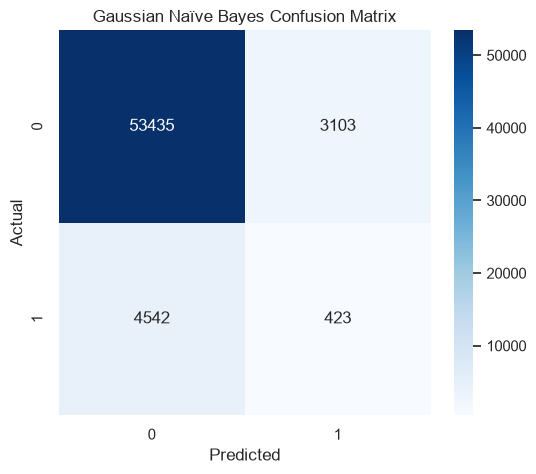

In [6]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Gaussian Naïve Bayes Confusion Matrix")

plt.show()

# Classification Report

The classification report provides detailed performance metrics for each class.

In [7]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.92      0.95      0.93     56538
           1       0.12      0.09      0.10      4965

    accuracy                           0.88     61503
   macro avg       0.52      0.52      0.52     61503
weighted avg       0.86      0.88      0.87     61503



# ROC Curve

The Receiver Operating Characteristic (ROC) Curve illustrates the classifier's ability to distinguish between default and non-default applicants.

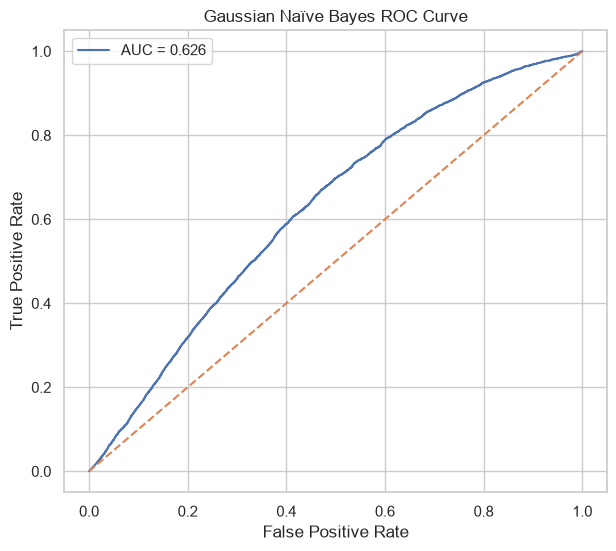

In [8]:
fpr, tpr, _ = roc_curve(y_test, y_prob)

plt.figure(figsize=(7,6))

plt.plot(
    fpr,
    tpr,
    label=f"AUC = {auc:.3f}"
)

plt.plot([0,1],[0,1],"--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Gaussian Naïve Bayes ROC Curve")

plt.legend()

plt.grid(True)

plt.show()

# Distribution of Predicted Default Probabilities

The predicted probability distribution provides insight into the confidence of the Gaussian Naïve Bayes classifier when estimating the likelihood of applicant default.

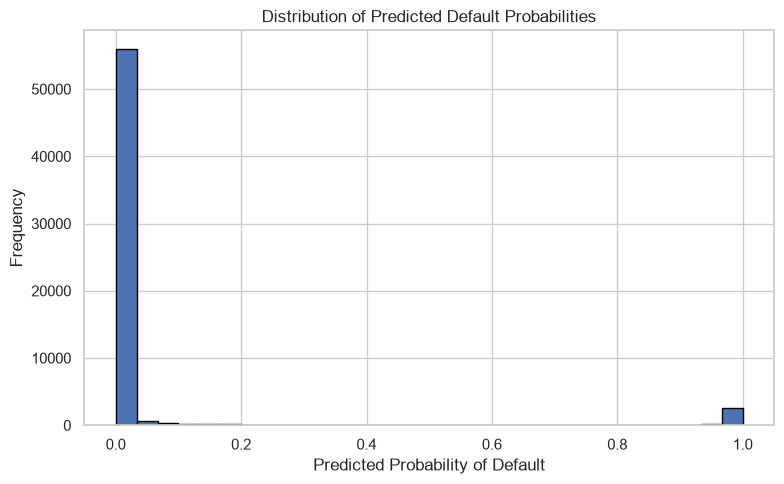

In [9]:
plt.figure(figsize=(8,5))

plt.hist(
    y_prob,
    bins=30,
    edgecolor="black"
)

plt.xlabel("Predicted Probability of Default")
plt.ylabel("Frequency")
plt.title("Distribution of Predicted Default Probabilities")

plt.tight_layout()

plt.show()

# Save Model Performance

The evaluation metrics of the Gaussian Naïve Bayes classifier are appended to the common model results file for comparison with all other machine learning models.

In [10]:
# ============================================================
# Save Model Performance
# ============================================================

from pathlib import Path

OUTPUT_DIR = Path("../results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

results_file = OUTPUT_DIR / "model_results.csv"

current_result = pd.DataFrame({

    "Model": ["Gaussian Naïve Bayes"],

    "Accuracy": [accuracy],

    "Precision": [precision],

    "Recall": [recall],

    "F1 Score": [f1],

    "ROC AUC": [auc],

    "False Positives": [cm[0,1]],

    "False Negatives": [cm[1,0]],

    "True Positives": [cm[1,1]],

    "True Negatives": [cm[0,0]]

})

if results_file.exists():

    existing_results = pd.read_csv(results_file)

    existing_results = pd.concat(
        [existing_results, current_result],
        ignore_index=True
    )

    existing_results.to_csv(
        results_file,
        index=False
    )

else:

    current_result.to_csv(
        results_file,
        index=False
    )

print("Model results saved successfully.")

current_result

Model results saved successfully.


,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC,False Positives,False Negatives,True Positives,True Negatives
0,Gaussian Naïve Bayes,0.875697,0.119966,0.085196,0.099635,0.626254,3103,4542,423,53435


# Conclusion

The Gaussian Naïve Bayes classifier was successfully trained and evaluated using the PCA-transformed applicant dataset.

## Key Outcomes

- A probabilistic classifier based on Bayes' Theorem was developed for credit risk prediction.
- Model performance was assessed using Accuracy, Precision, Recall, F1-Score, and ROC-AUC.
- The confusion matrix and ROC curve provided insight into the model's predictive ability.
- The distribution of predicted default probabilities highlighted the classifier's confidence across applicants.
- Performance metrics were recorded for comparison with the remaining machine learning models.

**Notebook Status:** ✅ Completed

**Next Notebook:** **Notebook 10 – Random Forest Classifier**